In [1]:
import numpy as np
import pandas as pd
from mhcgnomes import parse

# 1 Read total data

In [2]:
#DATA_PATH = '/home/denklewer/Data/' #ubuntu
EXPERIMENT_NAME = 'simple_model_enrichment'
DATA_PATH_BASE = 'G:/My Drive/Work/ITMO/data'
DATA_PATH = f'{DATA_PATH_BASE}/'

IEDB_DATA_PATH = DATA_PATH + 'Binding data/IEDB/mhc_ligand_full_single_file/mhc_ligand_full.csv'
NetMHCPan_41_DATA_PATH = DATA_PATH + 'Binding data/NetMHCpan-4.1/NetMHCpan_train/'
NetMHCIIPan_40_DATA_PATH = DATA_PATH + 'Binding data/NetMHCIIpan-4.0/NetMHCIIpan_train/NetMHCIIpan_train/'

In [3]:
netmhc = pd.read_csv(f"{NetMHCIIPan_40_DATA_PATH}/train_BA1.txt", sep="\t", header=None)

In [4]:
netmhc[2]

0        HLA-DPA10103-DPB10201
1        HLA-DPA10103-DPB10201
2        HLA-DPA10103-DPB10201
3        HLA-DPA10103-DPB10201
4        HLA-DPA10103-DPB10201
                 ...          
85362                  H-2-IEd
85363                  H-2-IEd
85364                  H-2-IEk
85365                  H-2-IEk
85366                  H-2-IEk
Name: 2, Length: 85367, dtype: object

In [5]:
netmhc[netmhc[2].str.startswith("H-2")][2].value_counts()

H-2-IAb    1251
H-2-IAd     478
H-2-IEd      96
H-2-IAs      90
H-2-IAk      70
H-2-IEk      49
H-2-IAu      27
H-2-IAq      11
Name: 2, dtype: int64

In [6]:
iedb_df = pd.read_csv(IEDB_DATA_PATH, sep=',', header=[0,1])


C:\Users\denkl\AppData\Local\Temp\ipykernel_92\4180061941.py:1: DtypeWarning: Columns (6,12,13,14,17,18,19,20,21,22,23,24,25,26,27,28,29,30,33,34,35,36,37,38,39,40,41,42,45,46,47,48,49,50,51,52,53,54,55,56,57,60,61,62,63,64,65,66,67,68,70,71,72,73,74,75,76,79,80,81,82,83,84,85,86,87,88,89,92,95,100,101,102,103,104,105,106,109) have mixed types. Specify dtype option on import or set low_memory=False.
  iedb_df = pd.read_csv(IEDB_DATA_PATH, sep=',', header=[0,1])


In [7]:
len(iedb_df)

4751412

In [8]:
iedb_df[('Epitope', 'Name')]

0                KLEDLERDL
1                LITGRLQSL
2                 TRVAFAGL
3                 RNTDFFGL
4                EVMPVSMAK
                ...       
4751407          EEVSLPSDP
4751408          EEVSLPSDP
4751409          EEVSLPSDP
4751410    SLQPLALEGSLQKRG
4751411    SLQPLALEGSLQKRG
Name: (Epitope, Name), Length: 4751412, dtype: object

In [9]:
iedb_df[('Epitope', 'Reference Name')]

0                     HDV 26-34
1                          S978
2                    OmpC 73-80
3                  OmpC 132-139
4          SARS Spike (707-715)
                   ...         
4751407               EEVSLPSDP
4751408               EEVSLPSDP
4751409               EEVSLPSDP
4751410                  C20-A1
4751411                  C20-A1
Name: (Epitope, Reference Name), Length: 4751412, dtype: object

In [10]:
iedb_df.columns[30:50]

MultiIndex([('Related Object',                'Name'),
            ('Related Object',   'Starting Position'),
            ('Related Object',     'Ending Position'),
            ('Related Object',                 'IRI'),
            ('Related Object',            'Synonyms'),
            ('Related Object',     'Source Molecule'),
            ('Related Object', 'Source Molecule IRI'),
            ('Related Object',     'Molecule Parent'),
            ('Related Object', 'Molecule Parent IRI'),
            ('Related Object',     'Source Organism'),
            ('Related Object', 'Source Organism IRI'),
            ('Related Object',             'Species'),
            ('Related Object',         'Species IRI'),
            (          'Host',                'Name'),
            (          'Host',                 'IRI'),
            (          'Host',         'Geolocation'),
            (          'Host',     'Geolocation IRI'),
            (          'Host',                 'Sex'),
          

In [11]:
def merge_column_name(column):
    return "_".join(column)

def filter_iedb_dataset(iedb_df, include_qualitative=True, include_mass_spec=True):
    QUALITATIVE_TO_AFFINITY_AND_INEQUALITY = {
    "Negative": (5000.0, ">"),
    "Positive": (500.0, "<"),  # used for mass-spec hits
    "Positive-High": (100.0, "<"),
    "Positive-Intermediate": (1000.0, "<"),
    "Positive-Low": (5000.0, "<"),
    }
    QUALITATIVE_TO_AFFINITY = dict(
        (key, value[0]) for (key, value)
        in QUALITATIVE_TO_AFFINITY_AND_INEQUALITY.items())
    QUALITATIVE_TO_INEQUALITY = dict(
        (key, value[1]) for (key, value)
        in QUALITATIVE_TO_AFFINITY_AND_INEQUALITY.items())
    
    
    
    print("Loaded iedb data: %s" % str(iedb_df.shape))
    filtered_df = iedb_df.copy()
    filtered_df = filtered_df[filtered_df[('Epitope', 'Object Type')] == "Linear peptide"]

    print("Linear peptides only, remaining: %d" % len(filtered_df))
    
    ## Clear bad data
    print("Subselecting to valid peptides (dropping peptides with PTMs). Starting with: %d" % len(filtered_df))
    filtered_df[('Epitope', 'Name')] = filtered_df[('Epitope', 'Name')].str.strip()
    filtered_df = filtered_df.loc[
        iedb_df[('Epitope', 'Name')].str.match("^[ACDEFGHIKLMNPQRSTVWY]+$")
    ]
    filtered_df = filtered_df.reset_index(drop=True)
    print("Now: %d" % len(filtered_df))
    
    
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("\+")]
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("X")]
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("B")]
#     filtered_df = filtered_df[~filtered_df[('Epitope', 'Description')].str.contains("Z")]
    filtered_df = filtered_df[[
    ('Epitope', 'Object Type'),
    ('Epitope', 'Name'),
    ('Epitope', 'Species'),
    ('Assay', 'Units'),
    ('Assay', 'Qualitative Measurement'),
    ('Assay', 'Quantitative measurement'),
     ('Assay', 'Measurement Inequality'),
    ('MHC Restriction', 'Name'),
    ('MHC Restriction', 'IRI'),
    ('MHC Restriction', 'Class'),
    ('Assay', 'Response measured'),
    ('Assay', 'Method'),
    ('Epitope', 'Molecule Parent IRI'),
    ('Epitope', 'Starting Position'),
    ('Epitope', 'Ending Position')
             ]]
    print("Subselecting assay groups as in Sarkizova. Starting with: %d" % len(filtered_df))

    assay_type1 = (filtered_df[('Assay', 'Response measured')] == 'half maximal effective concentration (EC50)') & \
                                              (filtered_df[('Assay', 'Method')] == 'purified MHC/direct/fluorescence')
    filtered_df = filtered_df[~assay_type1]
    assay_type2 = (filtered_df[('Assay', 'Response measured')] =='dissociation constant KD') & \
                                                  (filtered_df[('Assay', 'Method')] == 'purified MHC/direct/radioactivity')
    filtered_df = filtered_df[~assay_type2]
    assay_type3 = (filtered_df[('Assay', 'Response measured')] == 'half maximal effective concentration (EC50)') & \
                                                  (filtered_df[('Assay', 'Method')] == 'cellular MHC/direct/fluorescence')
    filtered_df = filtered_df[~assay_type3]
    filtered_df.columns = filtered_df.columns.map(merge_column_name)
    filtered_df = filtered_df.reset_index(drop=True)
    print("Now: %d" % len(filtered_df))


    quantitative = filtered_df.loc[filtered_df["Assay_Units"] == "nM"].copy()
    quantitative["measurement_type"] = "quantitative"
    quantitative = quantitative.rename(columns={"Assay_Measurement Inequality":"measurement_inequality"})
    quantitative['measurement_inequality'] = quantitative['measurement_inequality'].fillna("=").map(lambda s: {">=": ">", "<=": "<"}.get(s, s))
    print("Quantitative measurements: %d" % len(quantitative))
    # Ilya: remove quantitative measurement with no measurement values
    print("Dropping quantitative measurements with no measurement value")
    quantitative.dropna(subset = ["Assay_Quantitative measurement"], inplace=True)
    print("Quantitative measurements: %d" % len(quantitative))
    
    qualitative = filtered_df.loc[filtered_df["Assay_Units"] != "nM"].copy()
    qualitative["measurement_type"] = "qualitative"
    print("Qualitative measurements: %d" % len(qualitative))
    if not include_mass_spec:
        qualitative = qualitative.loc[
            (~qualitative["Assay_Method"].str.contains("mass spec"))
        ].copy()

    qualitative["Assay_Quantitative measurement"] = (
        qualitative["Assay_Qualitative Measurement"].map(QUALITATIVE_TO_AFFINITY))
    qualitative = qualitative.drop(columns=['Assay_Measurement Inequality'])
    qualitative["measurement_inequality"] = (qualitative["Assay_Qualitative Measurement"].map(QUALITATIVE_TO_INEQUALITY))
    print("Qualitative measurements (possibly after dropping MS): %d" % (
        len(qualitative)))
    
    filtered_df = pd.concat(
        (
            ([quantitative]) +
            ([qualitative] if include_qualitative else [])),
        ignore_index=True)
    print("Now: %d" % len(filtered_df))
    
    ## Mark binders
    binder_list = ['Positive', 'Positive-High', 'Positive-Intermediate', 'Positive-Low']
    non_binder_list = ['Negative']
    filtered_df.loc[filtered_df['Assay_Quantitative measurement'] <= 500, 'binder'] = 1
    filtered_df.loc[filtered_df['Assay_Quantitative measurement'] > 500, 'binder'] = 0
    #
    # filtered_df.loc[filtered_df['Qualitative Measure'].isin(binder_list),'binder'] = 1
    # filtered_df.loc[filtered_df['Qualitative Measure'].isin(non_binder_list),'binder'] = 0
    
    filtered_df.binder = filtered_df.binder.astype(int)
    filtered_df = filtered_df.drop(columns=[
     # 'Qualitative Measure',
     'Assay_Units',
     'Epitope_Object Type',
     'MHC Restriction_IRI'
     ])
    
    filtered_df = filtered_df.rename(columns={"MHC Restriction_Name":"allele", 
                                              "Epitope_Name":"peptide",
                                              "Assay_Quantitative measurement":"measurement_value",
                                              'Assay_Qualitative Measurement': "qualitative_measurement",
                                              "Epitope_Molecule Parent IRI":"protein_id",
                                              "Epitope_Starting Position":"peptide_start",
                                              "Epitope_Ending Position": "peptide_end"})
    filtered_df['length'] = filtered_df['peptide'].str.len()
    
    #filtered_df['allele'] = filtered_df['original_allele'].map(parse).to_string()
    
    print("Take unique (peptide, allele, length, 'measurement_value', 'measurement_inequality','qualitative_measurement' 'measurement_type', binder). Starting with: %d" % len(filtered_df))

    filtered_df = filtered_df.drop_duplicates([
    'peptide',
    'allele',
    'length',
    'measurement_value',
    'measurement_inequality',
    'measurement_type',
    'qualitative_measurement',
    'binder',
    'protein_id',
    'peptide_start',
    'peptide_end']).reset_index(drop=True)
    print("Now: %d" % len(filtered_df))

    
    print("Allele_distribution")
    print(filtered_df['allele'].value_counts()[:30])
    


    assert 'peptide' in filtered_df.columns
    assert 'allele' in filtered_df.columns
    assert 'length' in filtered_df.columns
    assert 'binder' in filtered_df.columns
    return filtered_df

In [12]:
#test_df = filter_iedb_dataset(iedb_df)
iedb_df = filter_iedb_dataset(iedb_df)


Loaded iedb data: (4751412, 111)
Linear peptides only, remaining: 4750644
Subselecting to valid peptides (dropping peptides with PTMs). Starting with: 4750644
Now: 4520115
Subselecting assay groups as in Sarkizova. Starting with: 4520115
Now: 4518490
Quantitative measurements: 238783
Dropping quantitative measurements with no measurement value
Quantitative measurements: 238626
Qualitative measurements: 4279707
Qualitative measurements (possibly after dropping MS): 4279707
Now: 4518333
Take unique (peptide, allele, length, 'measurement_value', 'measurement_inequality','qualitative_measurement' 'measurement_type', binder). Starting with: 4518333
Now: 2718132
Allele_distribution
HLA class I                  460978
HLA class II                 250672
HLA-DR                       102573
HLA-B*27:05                   94760
HLA-DRB1*15:01                89457
HLA-A*02:01                   82714
HLA-DRB1*03:01                78947
HLA-DRB1*13:02                73010
HLA-DRB1*13:01             

In [13]:
iedb_df.allele.value_counts()[:40]

HLA class I                  460978
HLA class II                 250672
HLA-DR                       102573
HLA-B*27:05                   94760
HLA-DRB1*15:01                89457
HLA-A*02:01                   82714
HLA-DRB1*03:01                78947
HLA-DRB1*13:02                73010
HLA-DRB1*13:01                71775
HLA-DRB1*01:03                70028
HLA-DRB1*15:02                70012
HLA-B*07:02                   32619
H2-Kb                         31702
HLA-B*57:01                   27653
HLA-A*01:01                   23585
HLA-B*15:02                   22714
H2-Db                         21955
Saha class I                  21939
HLA-A*24:02                   21909
H2-Kd                         21155
HLA-DRB1*01:01                20557
HLA-B*40:02                   20522
HLA-B*51:01                   20398
HLA-B*15:01                   20125
HLA-DRB1*07:01                19660
HLA-B*40:01                   18747
HLA-A*11:01                   18145
HLA-DPA1*01:03/DPB1*04:01   

In [15]:
iedb_df[iedb_df.allele.str.contains('Q')].allele

1376       HLA-DQA1*03:01/DQB1*03:01
1377       HLA-DQA1*03:01/DQB1*03:01
1378       HLA-DQA1*03:01/DQB1*03:01
1379       HLA-DQA1*03:01/DQB1*03:01
1380       HLA-DQA1*03:01/DQB1*03:01
                     ...            
2717032    HLA-DQA1*01:02/DQB1*03:01
2717038    HLA-DQA1*05:01/DQB1*02:01
2717039    HLA-DQA1*01:02/DQB1*03:03
2717040    HLA-DQA1*01:02/DQB1*06:02
2717041    HLA-DQA1*05:05/DQB1*03:01
Name: allele, Length: 61020, dtype: object

In [16]:
ALLELES = [
    # 'H2-IAb',
    # 'H2-IAd',
    # 'H2-IAk',
    # 'H2-IAq',
    # 'H2-IAs',
    # 'H2-IAu',
    # 'H2-IEd',
    # 'H2-IAk',
     'H2-Kb',
     'H2-Db',
    'HLA-A*02:01',
    'HLA-A*03:01',
    'HLA-A*01:01',
    'HLA-A*24:02',
    'HLA-B*27:05',
    'HLA-B*07:02',
    'HLA-B*57:01',
    'HLA-B*15:02',
    'HLA-C*12:02',
    #'HLA-A*24:02',
    #'HLA-A*11:01',
    'HLA-DRB1*01:01',
    'HLA-DRB1*04:01',
    'HLA-DRB1*07:01',
    'HLA-DRB1*04:04',
    #'HLA-DRB1*04:01',
    #'HLA-DRB1*15:01',
    #'HLA-DRB3*01:01',
    #'HLA-DRB5*01:01',
    'HLA-DPA1*01:03/DPB1*04:01',
    'HLA-DPA1*02:02/DPB1*05:01'
]



In [17]:
target_df = iedb_df[iedb_df.allele.isin(ALLELES)]

In [18]:
target_df.allele.value_counts(dropna=False)

HLA-B*27:05                  94760
HLA-A*02:01                  82714
HLA-B*07:02                  32619
H2-Kb                        31702
HLA-B*57:01                  27653
HLA-A*01:01                  23585
HLA-B*15:02                  22714
H2-Db                        21955
HLA-A*24:02                  21909
HLA-DRB1*01:01               20557
HLA-DRB1*07:01               19660
HLA-DPA1*01:03/DPB1*04:01    17128
HLA-A*03:01                  17027
HLA-DRB1*04:01               16230
HLA-DRB1*04:04               13872
HLA-DPA1*02:02/DPB1*05:01    13492
HLA-C*12:02                  11205
Name: allele, dtype: int64

In [19]:
target_df.binder.value_counts(dropna=False)

1    394046
0     94736
Name: binder, dtype: int64

# Make per allele DF

In [20]:
def make_per_allele_df(source_df, ALLELES):
    per_allele_df = dict()
    for allele_name in ALLELES:
        allele_df = source_df[source_df['allele'] == allele_name] 
        print(f"------Allele {allele_name} ----------")
        print("Binders_distribution:")
        print(allele_df['binder'].value_counts())
        print("Length_distribution:")
        print(allele_df['length'].value_counts().iloc[:10])
        per_allele_df[allele_name] = allele_df
    return per_allele_df
        
        
per_allele_df = make_per_allele_df(iedb_df, ALLELES)

------Allele H2-Kb ----------
Binders_distribution:
1    29046
0     2656
Name: binder, dtype: int64
Length_distribution:
8     9612
9     7620
10    2886
11    2051
12    1518
13    1350
14    1216
15    1060
7     1045
16     941
Name: length, dtype: int64
------Allele H2-Db ----------
Binders_distribution:
1    19040
0     2915
Name: binder, dtype: int64
Length_distribution:
9     8395
10    3642
8     2498
11    2412
12     884
13     742
14     672
15     531
7      521
16     462
Name: length, dtype: int64
------Allele HLA-A*02:01 ----------
Binders_distribution:
1    68801
0    13913
Name: binder, dtype: int64
Length_distribution:
9     50381
10    14263
11     5983
8      3786
12     1968
7      1553
13     1059
15      850
14      799
16      569
Name: length, dtype: int64
------Allele HLA-A*03:01 ----------
Binders_distribution:
1    10930
0     6097
Name: binder, dtype: int64
Length_distribution:
9     11307
10     3773
11     1151
12      325
8       172
13      159
14     

In [21]:
df = iedb_df[iedb_df.allele.isin(ALLELES)]

In [22]:
per_allele_df[ALLELES[0]].length.value_counts()

8     9612
9     7620
10    2886
11    2051
12    1518
13    1350
14    1216
15    1060
7     1045
16     941
17     757
18     626
20     481
19     464
21      38
22       9
23       9
24       8
6        7
28       1
34       1
30       1
2        1
Name: length, dtype: int64

Text(0.5, 0.98, 'Dataset size for each Allele')

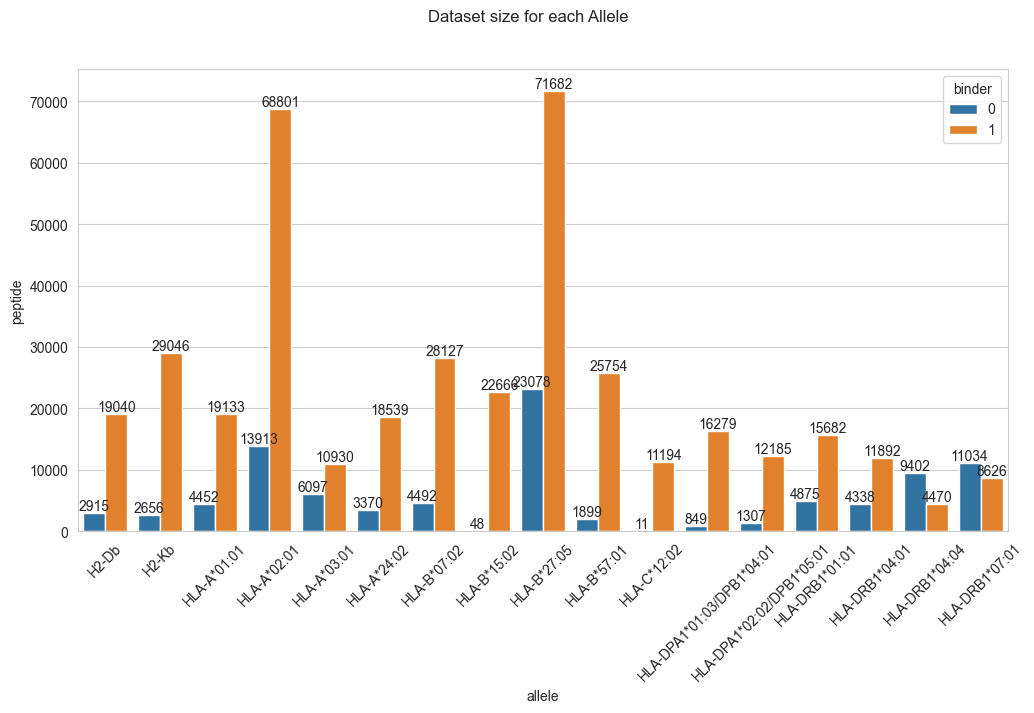

In [23]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
#target_df = df[df['binder'] == 1]
ax = sns.barplot(data=df.groupby(['binder','allele'], as_index=False)['peptide'].count(), x='allele', y='peptide', hue='binder', orient='vertical')
for container in ax.containers:
    ax.bar_label(container)
#sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
for item in ax.get_xticklabels():
    item.set_rotation(45)

ax.figure.suptitle('Dataset size for each Allele')

#  Save per allele DF

In [24]:
allele_name = "HLA-DRB1*0101"

In [25]:
import mhcnames
import mhcgnomes



TARGET_PATH_TO_FILES = DATA_PATH + EXPERIMENT_NAME + '/' 

import mhcnames
import os
if not os.path.exists(TARGET_PATH_TO_FILES ):
    os.makedirs(TARGET_PATH_TO_FILES )


for allele_name in ALLELES:
    total_df = per_allele_df[allele_name]
    compact_name = mhcgnomes.parse(allele_name).compact_string(include_species=True).replace("*", "_")
    print(compact_name)
    
    #mhcnames.compact_allele_name(allele_name,)
    # allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    total_df.to_csv("{}data#{}.csv".format(TARGET_PATH_TO_FILES,compact_name),sep=";", index=False)

H2-Kb
H2-Db
HLA-A0201
HLA-A0301
HLA-A0101
HLA-A2402
HLA-B2705
HLA-B0702
HLA-B5701
HLA-B1502
HLA-C1202
HLA-DRB1_0101
HLA-DRB1_0401
HLA-DRB1_0701
HLA-DRB1_0404
HLA-DPA1_0103-DPB1_0401
HLA-DPA1_0202-DPB1_0501


In [24]:
total_df['binder'].value_counts()

1    12185
0     1307
Name: binder, dtype: int64